# Лабораторная работа: Геометрические и аффинные преобразования изображений
**Вариант 3**
**Задачи:**
1. Увеличить изображение в 1.5 раза.
2. Повернуть изображение на 120°.
3. Сместить изображение на 50 пикселей влево и 30 вниз.
4. Сделать двойное отражение (сначала по вертикали, затем по горизонтали).
5. Выполнить аффинное преобразование по трём произвольным точкам.

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def show_comparison(original, modified, title_modified):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Исходное ({original.shape[1]}x{original.shape[0]})")
    axes[0].axis('on')
    
    axes[1].imshow(cv2.cvtColor(modified, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"{title_modified} ({modified.shape[1]}x{modified.shape[0]})")
    axes[1].axis('on')
    
    plt.tight_layout()
    plt.show()

img = cv2.imread('image.jpg')

if img is None:
    print("Файл 'image.jpg' не найден. Создаём тестовое изображение...")
    img = np.full((300, 300, 3), 240, dtype=np.uint8)
    cv2.rectangle(img, (40, 40), (140, 140), (0, 0, 255), -1)
    cv2.circle(img, (220, 80), 40, (0, 255, 0), -1)
    cv2.putText(img, "F", (120, 250), cv2.FONT_HERSHEY_SIMPLEX, 3, (255, 0, 0), 5)

h, w = img.shape[:2]

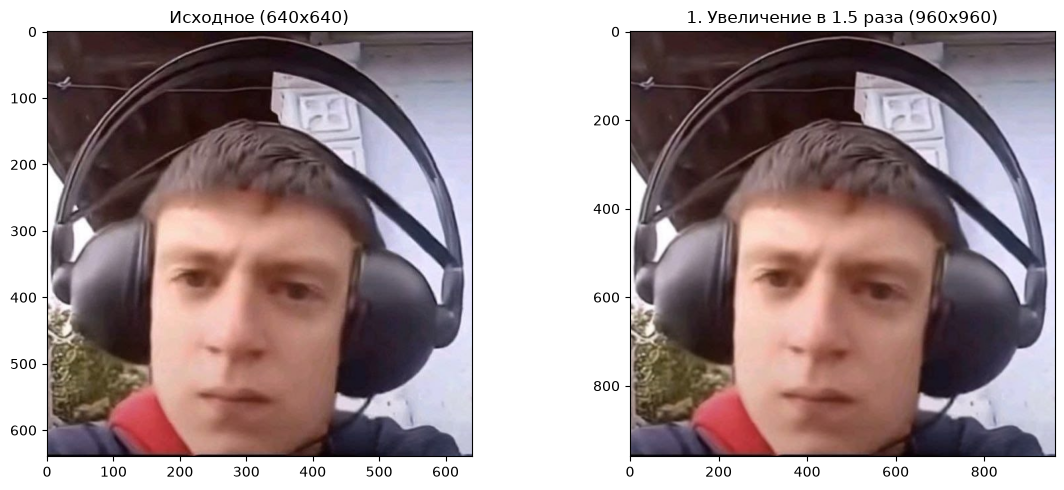

In [16]:
scaled_img = cv2.resize(img, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_LINEAR)
show_comparison(img, scaled_img, "1. Увеличение в 1.5 раза")

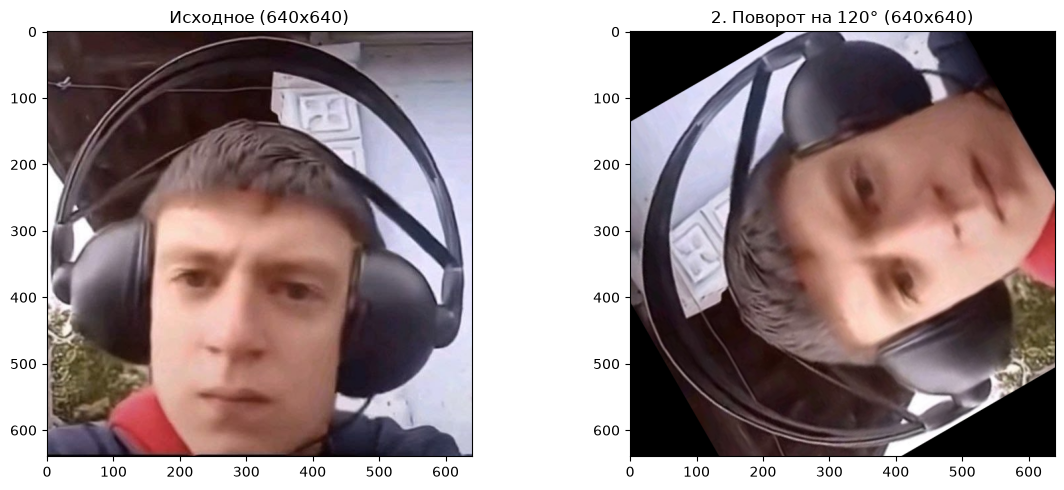

In [17]:
center = (w // 2, h // 2)
rotation_matrix = cv2.getRotationMatrix2D(center, 120, 1.0)
rotated_img = cv2.warpAffine(img, rotation_matrix, (w, h))
show_comparison(img, rotated_img, "2. Поворот на 120°")

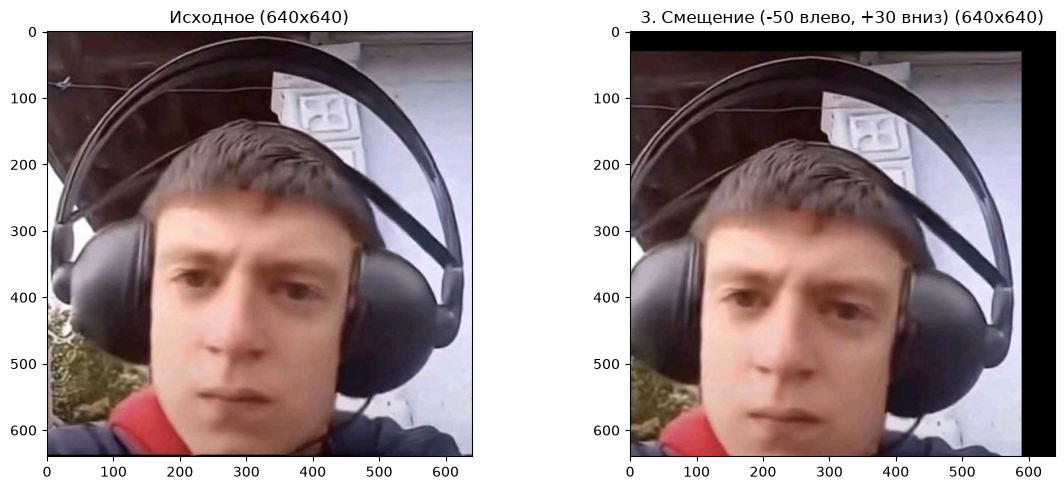

In [18]:
translation_matrix = np.float32([
    [1, 0, -50],
    [0, 1, 30]
])
shifted_img = cv2.warpAffine(img, translation_matrix, (w, h))
show_comparison(img, shifted_img, "3. Смещение (-50 влево, +30 вниз)")

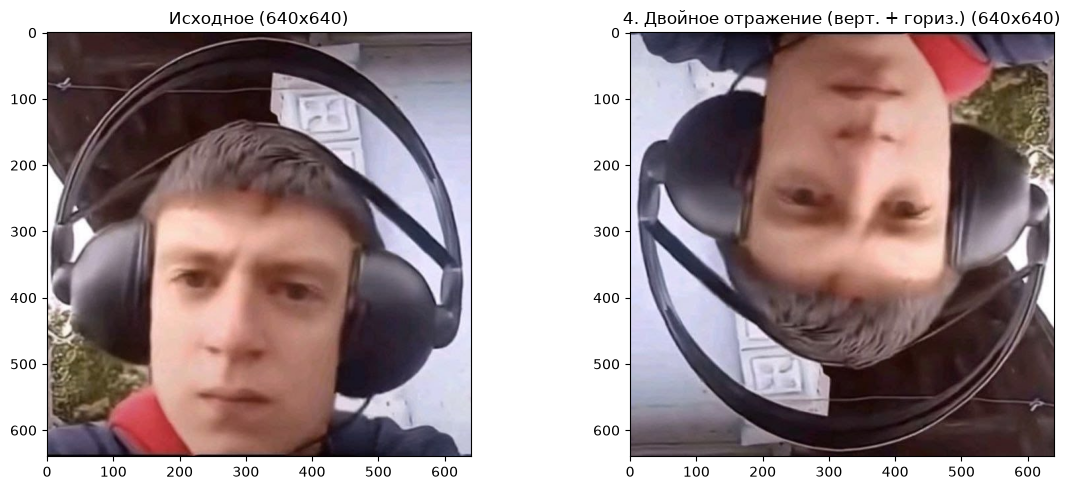

In [19]:
flip_v = cv2.flip(img, 0)
double_flip_img = cv2.flip(flip_v, 1)
show_comparison(img, double_flip_img, "4. Двойное отражение (верт. + гориз.)")

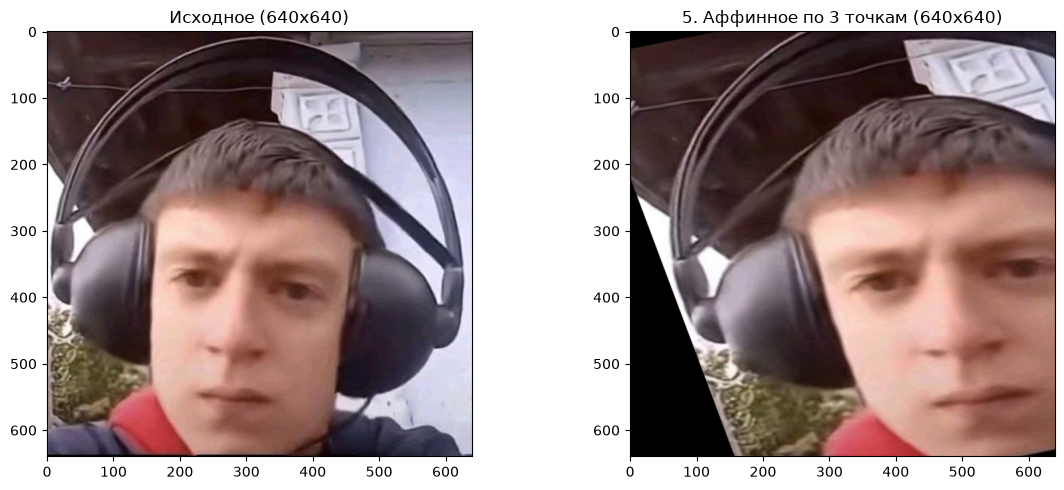

In [20]:
pts1 = np.float32([
    [50, 50],
    [200, 50],
    [50, 200]
])

pts2 = np.float32([
    [20, 80],
    [220, 40],
    [80, 240]
])

affine_matrix = cv2.getAffineTransform(pts1, pts2)
affine_transformed_img = cv2.warpAffine(img, affine_matrix, (w, h))

show_comparison(img, affine_transformed_img, "5. Аффинное по 3 точкам")

### Ответы на контрольные вопросы:

1. **Какая функция в OpenCV применяется для аффинных преобразований?**
   * Для непосредственного применения преобразования к изображению используется функция **`cv2.warpAffine()`**.
   * Для получения самой матрицы аффинного преобразования ($2 \times 3$) используются функции:
     * **`cv2.getAffineTransform(pts1, pts2)`** — вычисление матрицы по 3 исходным и 3 целевым неколлинеарным точкам;
     * **`cv2.getRotationMatrix2D(center, angle, scale)`** — создание матрицы вращения вокруг заданной точки с одновременным масштабированием.

2. **Что произойдет с параллельными прямыми при аффинном преобразовании?**
   * При аффинном преобразовании **параллельные прямые остаются строго параллельными** (сохраняется свойство параллельности). 
   * В отличие от проективных (перспективных) преобразований, где параллельные прямые могут пересекаться в точке схода (vanishing point), аффинные преобразования сохраняют коллинеарность точек и отношение отрезков на параллельных прямых.